# Benchmark systématique de shallow-CNN — Bonn EEG

Classification binaire **ictal / non-ictal**.

## Structure
## Labels
- A, B, C, D -> `0` (non-ictal)
- E -> `1` (ictal)

## Protocole
- Test jamais utilise pour la selection.
- Validation extraite du train, stratifiee par A–E.
- Stats de normalisation apprises sur le train seulement.
- Meilleur modele choisi sur balanced accuracy + sensibilite ictale en validation.

In [1]:
from __future__ import annotations
import csv, itertools, json, random, time
from pathlib import Path
import numpy as np, pandas as pd, torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)
import matplotlib.pyplot as plt

In [2]:
DOSSIER_DONNEES = Path("pipeline_notch50_bp0.5_80_impulse2.5")
DOSSIER_SORTIE = Path("resultats_shallow_cnn")
CLASSES_ORIGINALES = ["A","B","C","D","E"]
CLASSES_NON_ICTALES = ["A","B","C","D"]
CLASSE_ICTALE = "E"
FS = 173.61
VALIDATION_FRACTION = 0.20
SEEDS = [0,1,2]
EPOCHS_MAX = 100
PATIENCE = 12
BATCH_SIZE = 32
NUM_WORKERS = 0
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FOCAL_LOSS = False
COMPARER_FOCAL_LOSS = True
BALANCING_MODE = "all"
NORMALIZATION = "per_segment"
ARCHITECTURES = [
    {"name":"shallow_square_log","kind":"shallow","filters":16,"kernel_size":25,"pool_size":75,"dropout":0.5},
    {"name":"cnn1d_small","kind":"cnn","filters":16,"kernel_size":7,"pool_size":2,"dropout":0.3},
    {"name":"cnn1d_medium","kind":"cnn","filters":32,"kernel_size":15,"pool_size":4,"dropout":0.5},
    {"name":"cnn1d_multiscale","kind":"multiscale","filters":16,"kernel_size":7,"pool_size":2,"dropout":0.5},
]
LEARNING_RATES = [1e-3, 3e-4]
WEIGHT_DECAYS = [0.0, 1e-4]
OPTIMIZERS = ["adam"]
print("Device :", DEVICE)

Device : cuda


In [3]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [4]:
def load_class_folder(split, classe):
    folder = DOSSIER_DONNEES / split / classe
    if not folder.exists():
        raise FileNotFoundError(f"Dossier absent : {folder.resolve()}")
    files = sorted(folder.glob("segment_*.npy"))
    if not files: raise FileNotFoundError(f"Aucun segment dans {folder}")
    signals = [np.asarray(np.load(f, allow_pickle=False), dtype=np.float32).squeeze() for f in files]
    if len({x.shape for x in signals}) != 1 or any(x.ndim != 1 for x in signals):
        raise ValueError(f"Signaux non homogenes dans {folder}")
    return np.stack(signals), [f.name for f in files]

def load_split(split):
    xs, ys, groups = [], [], []
    for c in CLASSES_ORIGINALES:
        x, _ = load_class_folder(split, c)
        y = 1 if c == CLASSE_ICTALE else 0
        xs.append(x); ys.extend([y]*len(x)); groups.extend([c]*len(x))
    return np.concatenate(xs), np.asarray(ys, dtype=np.int64), np.asarray(groups)

def split_train_validation(x, y, groups, seed):
    tr_idx, va_idx = [], []
    for c in CLASSES_ORIGINALES:
        idx = np.flatnonzero(groups == c)
        if len(idx) < 2: raise ValueError(f"Pas assez d'exemples de {c}.")
        tr, va = train_test_split(idx, test_size=VALIDATION_FRACTION, random_state=seed)
        tr_idx.extend(tr.tolist()); va_idx.extend(va.tolist())
    return np.asarray(tr_idx), np.asarray(va_idx)

In [5]:
def normalize_data(x_train, x_val, x_test, mode):
    eps = 1e-8
    if mode == "per_segment":
        def z(x):
            m = x.mean(axis=1, keepdims=True); s = x.std(axis=1, keepdims=True)
            return (x - m) / np.maximum(s, eps)
        return z(x_train), z(x_val), z(x_test), {"mode": mode}
    if mode == "train_global":
        m = float(x_train.mean()); s = max(float(x_train.std()), eps)
        return ((x_train-m)/s, (x_val-m)/s, (x_test-m)/s,
                {"mode": mode, "mean_train": m, "std_train": s})
    raise ValueError(f"Normalisation inconnue : {mode}")

In [6]:
def balance_train_indices(y, groups, seed):
    rng = np.random.RandomState(seed)
    ictal = np.flatnonzero(y == 1); nonictal = np.flatnonzero(y == 0)
    target = len(ictal)
    if len(nonictal) <= target: return np.arange(len(y))
    gc = {c: int(np.sum(groups[nonictal] == c)) for c in CLASSES_NON_ICTALES}
    tot = sum(gc.values())
    q = {c: target * gc[c] / tot for c in CLASSES_NON_ICTALES}
    alloc = {c: int(np.floor(q[c])) for c in CLASSES_NON_ICTALES}
    rem = target - sum(alloc.values())
    for c in sorted(CLASSES_NON_ICTALES, key=lambda k: q[k]-alloc[k], reverse=True)[:rem]:
        alloc[c] += 1
    sel = []
    for c in CLASSES_NON_ICTALES:
        idx = np.flatnonzero((y == 0) & (groups == c))
        sel.extend(rng.choice(idx, size=min(alloc[c], len(idx)), replace=False).tolist())
    if len(sel) < target:
        rest = np.setdiff1d(nonictal, np.asarray(sel, dtype=int))
        sel.extend(rng.choice(rest, size=target-len(sel), replace=False).tolist())
    return np.asarray(sorted(sel + ictal.tolist()), dtype=int)

In [7]:
class ShallowSquareLog(nn.Module):
    def __init__(self, filters=16, kernel_size=25, pool_size=75, dropout=0.5):
        super().__init__()
        self.temporal = nn.Conv1d(1, filters, kernel_size, padding="same", bias=False)
        self.bn = nn.BatchNorm1d(filters)
        self.pool = nn.AvgPool1d(pool_size, stride=max(1, pool_size // 2))
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(filters, 2)
    def forward(self, x):
        x = self.bn(self.temporal(x)).square()
        x = self.pool(x)
        x = torch.log(torch.clamp(x, min=1e-6))
        return self.classifier(self.dropout(x.mean(dim=-1)))

class CNN1D(nn.Module):
    def __init__(self, filters=16, kernel_size=7, pool_size=2, dropout=0.3):
        super().__init__(); f = filters
        self.features = nn.Sequential(
            nn.Conv1d(1, f, kernel_size, padding="same", bias=False),
            nn.BatchNorm1d(f), nn.ReLU(), nn.MaxPool1d(pool_size),
            nn.Conv1d(f, 2*f, kernel_size, padding="same", bias=False),
            nn.BatchNorm1d(2*f), nn.ReLU(), nn.MaxPool1d(pool_size),
            nn.Conv1d(2*f, 2*f, kernel_size, padding="same", bias=False),
            nn.BatchNorm1d(2*f), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(2*f, 2))
    def forward(self, x): return self.classifier(self.features(x))

class MultiScaleCNN(nn.Module):
    def __init__(self, filters=16, kernel_size=7, pool_size=2, dropout=0.5):
        super().__init__(); f = filters
        self.branches = nn.ModuleList([
            nn.Sequential(nn.Conv1d(1, f, k, padding="same", bias=False),
                          nn.BatchNorm1d(f), nn.ReLU(), nn.MaxPool1d(pool_size),
                          nn.AdaptiveAvgPool1d(1)) for k in [3, 7, 15]])
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(3*f, 2))
    def forward(self, x):
        return self.classifier(torch.cat([b(x) for b in self.branches], dim=1))

def build_model(cfg):
    if cfg["kind"] == "shallow":
        return ShallowSquareLog(cfg["filters"], cfg["kernel_size"], cfg["pool_size"], cfg["dropout"])
    if cfg["kind"] == "cnn":
        return CNN1D(cfg["filters"], cfg["kernel_size"], cfg["pool_size"], cfg["dropout"])
    if cfg["kind"] == "multiscale":
        return MultiScaleCNN(cfg["filters"], cfg["kernel_size"], cfg["pool_size"], cfg["dropout"])
    raise ValueError(cfg["kind"])

In [8]:
class FocalLoss(nn.Module):
    def __init__(self, alpha, gamma=2.0):
        super().__init__(); self.register_buffer("alpha", alpha); self.gamma = gamma
    def forward(self, logits, targets):
        lp = torch.log_softmax(logits, dim=1)
        lpt = lp.gather(1, targets[:, None]).squeeze(1)
        pt = lpt.exp()
        return (-self.alpha[targets] * (1.0 - pt).pow(self.gamma) * lpt).mean()

def make_loss(y_train, focal):
    if not focal: return nn.CrossEntropyLoss()
    c = np.bincount(y_train, minlength=2).astype(np.float32)
    w = c.sum() / (2.0 * np.maximum(c, 1.0)); w = w / w.mean()
    return FocalLoss(torch.tensor(w, dtype=torch.float32, device=DEVICE), gamma=2.0)

In [9]:
def make_loader(x, y, shuffle):
    return DataLoader(TensorDataset(
        torch.tensor(x, dtype=torch.float32).unsqueeze(1),
        torch.tensor(y, dtype=torch.long)),
        batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
        pin_memory=(DEVICE == "cuda"))

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval(); tl, tn = 0.0, 0; ps, ys = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        lg = model(xb); loss = criterion(lg, yb)
        tl += float(loss.item()) * len(yb); tn += len(yb)
        ps.append(torch.softmax(lg, dim=1)[:, 1].cpu().numpy()); ys.append(yb.cpu().numpy())
    y = np.concatenate(ys); p = np.concatenate(ps); pr = (p >= 0.5).astype(int)
    m = {"loss": tl / max(tn, 1),
         "accuracy": accuracy_score(y, pr),
         "balanced_accuracy": balanced_accuracy_score(y, pr),
         "precision_ictal": precision_score(y, pr, zero_division=0),
         "recall_sensitivity_ictal": recall_score(y, pr, zero_division=0),
         "specificity_non_ictal": recall_score(1-y, 1-pr, zero_division=0),
         "f1_ictal": f1_score(y, pr, zero_division=0),
         "confusion_matrix": confusion_matrix(y, pr, labels=[0, 1]).tolist()}
    m["roc_auc"] = roc_auc_score(y, p) if len(np.unique(y)) == 2 else float("nan")
    return m

def fit_one(config, x_train, y_train, x_val, y_val, seed, focal_loss):
    set_seed(seed)
    model = build_model(config).to(DEVICE)
    criterion = make_loss(y_train, focal_loss)
    opt = torch.optim.Adam(model.parameters(), lr=config["learning_rate"],
                           weight_decay=config["weight_decay"])
    tl = make_loader(x_train, y_train, True); vl = make_loader(x_val, y_val, False)
    bvl, bst, be, st = float("inf"), None, 0, 0; hist = []
    for ep in range(1, EPOCHS_MAX+1):
        model.train(); rl, seen = 0.0, 0
        for xb, yb in tl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb); loss.backward(); opt.step()
            rl += float(loss.item()) * len(yb); seen += len(yb)
        vm = evaluate(model, vl, criterion)
        hist.append({"epoch": ep, "train_loss": rl/max(seen,1),
                     "val_loss": vm["loss"], "val_balanced_accuracy": vm["balanced_accuracy"]})
        if vm["loss"] < bvl - 1e-5:
            bvl = vm["loss"]; st = 0
            bst = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            be = ep
        else:
            st += 1
            if st >= PATIENCE: break
    if bst is None: raise RuntimeError("Pas d'etat sauvegarde.")
    model.load_state_dict(bst)
    return model, be, hist, evaluate(model, vl, criterion)

In [10]:
def run_benchmark():
    DOSSIER_SORTIE.mkdir(parents=True, exist_ok=True)
    x_train_full, y_train_full, g_train_full = load_split("entrainement")
    x_test, y_test, g_test = load_split("test")
    if x_train_full.shape[1] != x_test.shape[1]:
        raise ValueError("Longueurs differentes train/test.")
    print(f"Device : {DEVICE}")
    print(f"Train : {len(y_train_full)} ; test : {len(y_test)}")
    results, best, rid = [], None, 0
    for arch, lr, wd, nm, focal, bm, seed in itertools.product(
        ARCHITECTURES, LEARNING_RATES, WEIGHT_DECAYS,
        ["per_segment", "train_global"],
        ([False, True] if COMPARER_FOCAL_LOSS else [FOCAL_LOSS]),
        ["all", "balanced"], SEEDS):
        if focal and bm == "balanced": continue
        ab = "balanced" if (not focal and bm == "balanced") else "all"
        rid += 1
        print(f"[{rid}] {arch['name']} lr={lr:g} wd={wd:g} norm={nm} focal={focal} bal={ab} seed={seed}")
        tr, va = split_train_validation(x_train_full, y_train_full, g_train_full, seed)
        xt, yt, gt = x_train_full[tr], y_train_full[tr], g_train_full[tr]
        xv, yv = x_train_full[va], y_train_full[va]
        if ab == "balanced":
            k = balance_train_indices(yt, gt, seed); xt, yt = xt[k], yt[k]
        xt, xv, _, nm_meta = normalize_data(xt, xv, x_test, nm)
        cfg = dict(arch); cfg.update({"learning_rate": lr, "weight_decay": wd})
        t0 = time.time()
        model, be, hist, vm = fit_one(cfg, xt, yt, xv, yv, seed, focal)
        el = time.time() - t0
        rec = {"run_id": rid, "architecture": arch["name"], "learning_rate": lr,
               "weight_decay": wd, "normalization": nm, "focal_loss": focal,
               "focal_gamma": 2.0 if focal else None, "balancing_mode": ab,
               "seed": seed, "n_train_after_sampling": len(yt), "n_val": len(yv),
               "best_epoch": be, "runtime_seconds": round(el, 2),
               "normalization_metadata": json.dumps(nm_meta),
               **{f"val_{k}": v for k, v in vm.items() if k != "confusion_matrix"},
               "val_confusion_matrix": json.dumps(vm["confusion_matrix"])}
        results.append(rec)
        sc = (vm["balanced_accuracy"], vm["recall_sensitivity_ictal"])
        if best is None or sc > best["score"]:
            best = {"score": sc,
                    "model_state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                    "config": cfg, "seed": seed, "normalization": nm_meta,
                    "focal_loss": focal, "balancing_mode": ab,
                    "architecture": arch["name"], "best_epoch": be,
                    "train_class_counts": np.bincount(yt, minlength=2).tolist()}
        pre = (f"{rid:04d}_{arch['name']}_norm-{nm}_focal-{int(focal)}"
               f"_bal-{ab}_lr-{lr:g}_wd-{wd:g}_seed-{seed}")
        with open(DOSSIER_SORTIE / f"{pre}_history.json", "w", encoding="utf-8") as f:
            json.dump(hist, f, indent=2)
        torch.save({"model_state_dict": model.state_dict(), "config": cfg,
                    "best_epoch": be, "normalization": nm_meta},
                   DOSSIER_SORTIE / f"{pre}_model.pt")
        with open(DOSSIER_SORTIE / "results.csv", "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=list(results[0].keys()))
            w.writeheader(); w.writerows(results)
    df = pd.DataFrame(results)
    metrics = ["val_balanced_accuracy","val_accuracy","val_precision_ictal",
               "val_recall_sensitivity_ictal","val_specificity_non_ictal",
               "val_f1_ictal","val_roc_auc"]
    gcols = ["architecture","learning_rate","weight_decay",
             "normalization","focal_loss","balancing_mode"]
    summ = df.groupby(gcols)[metrics].agg(["mean","std"]).reset_index()
    summ.to_csv(DOSSIER_SORTIE / "summary_by_configuration.csv", index=False)
    df.sort_values(["val_balanced_accuracy","val_recall_sensitivity_ictal"],ascending=False).to_csv(
        DOSSIER_SORTIE / "results_sorted_validation_selected.csv", index=False)
    print(f"\nTermine : {DOSSIER_SORTIE.resolve()}")
    print(summ.to_string(index=False))
    return df, summ, best

In [11]:
df, summary, best_candidate = run_benchmark()

Device : cuda
Train : 460 ; test : 40
[1] shallow_square_log lr=0.001 wd=0 norm=per_segment focal=False bal=all seed=0
[2] shallow_square_log lr=0.001 wd=0 norm=per_segment focal=False bal=all seed=1
[3] shallow_square_log lr=0.001 wd=0 norm=per_segment focal=False bal=all seed=2
[4] shallow_square_log lr=0.001 wd=0 norm=per_segment focal=False bal=balanced seed=0
[5] shallow_square_log lr=0.001 wd=0 norm=per_segment focal=False bal=balanced seed=1
[6] shallow_square_log lr=0.001 wd=0 norm=per_segment focal=False bal=balanced seed=2
[7] shallow_square_log lr=0.001 wd=0 norm=per_segment focal=True bal=all seed=0
[8] shallow_square_log lr=0.001 wd=0 norm=per_segment focal=True bal=all seed=1
[9] shallow_square_log lr=0.001 wd=0 norm=per_segment focal=True bal=all seed=2
[10] shallow_square_log lr=0.001 wd=0 norm=train_global focal=False bal=all seed=0
[11] shallow_square_log lr=0.001 wd=0 norm=train_global focal=False bal=all seed=1
[12] shallow_square_log lr=0.001 wd=0 norm=train_global

KeyError: "Columns not found: 'precision_ictal', 'f1_ictal', 'recall_sensitivity_ictal', 'specificity_non_ictal', 'balanced_accuracy', 'accuracy', 'roc_auc'"

In [12]:
# On recharge results.csv déjà produit (le crash est survenu après son écriture)
df = pd.read_csv(DOSSIER_SORTIE / "results.csv")

# CORRECTION : les métriques ont le préfixe "val_" dans le DataFrame
metrics = ["val_balanced_accuracy", "val_accuracy", "val_precision_ictal",
           "val_recall_sensitivity_ictal", "val_specificity_non_ictal",
           "val_f1_ictal", "val_roc_auc"]
gcols = ["architecture", "learning_rate", "weight_decay",
         "normalization", "focal_loss", "balancing_mode"]

summary = df.groupby(gcols)[metrics].agg(["mean", "std"]).reset_index()
summary.to_csv(DOSSIER_SORTIE / "summary_by_configuration.csv", index=False)

# CORRECTION : même préfixe pour le tri
df.sort_values(["val_balanced_accuracy", "val_recall_sensitivity_ictal"],
               ascending=False).to_csv(
    DOSSIER_SORTIE / "results_sorted_validation_selected.csv", index=False)

print(f"Résumé écrit : {DOSSIER_SORTIE / 'summary_by_configuration.csv'}")
print(f"{len(df)} runs chargés, {summary.shape[0]} configurations résumées")
summary.head()

Résumé écrit : resultats_shallow_cnn/summary_by_configuration.csv
288 runs chargés, 96 configurations résumées


architecture learning_rate weight_decay normalization focal_loss  \
                                                                      
0  cnn1d_medium        0.0003          0.0   per_segment      False   
1  cnn1d_medium        0.0003          0.0   per_segment      False   
2  cnn1d_medium        0.0003          0.0   per_segment       True   
3  cnn1d_medium        0.0003          0.0  train_global      False   
4  cnn1d_medium        0.0003          0.0  train_global      False   

  balancing_mode val_balanced_accuracy           val_accuracy            \
                                  mean       std         mean       std   
0            all              0.914474  0.048596     0.967391  0.018827   
1       balanced              0.864583  0.047735     0.952899  0.016604   
2            all              0.942982  0.012345     0.960145  0.012551   
3            all              0.989583  0.018042     0.996377  0.006276   
4       balanced              0.972588  0.019204     0.981884  0.012551   

  val_precision_ictal           val_recall_sensitivity_ictal            \
                 mean       std                         mean       std   
0            0.976190  0.041239                     0.833333  0.095470   
1            1.000000  0.000000                     0.729167  0.095470   
2            0.868387  0.072940                     0.916667  0.036084   
3            1.000000  0.000000                     0.979167  0.036084   
4            0.941176  0.058824                     0.958333  0.036084   

  val_specificity_non_ictal           val_f1_ictal           val_roc_auc  \
                       mean       std         mean       std        mean   
0                  0.995614  0.007597     0.897184  0.061290    0.992050   
1                  1.000000  0.000000     0.840975  0.065182    0.979715   
2                  0.969298  0.020099     0.889820  0.028451    0.984101   
3                  1.000000  0.000000     0.989247  0.018624    1.000000   
4                  0.986842  0.013158     0.948843  0.034440    0.997807   

             
        std  
0  0.004748  
1  0.011165  
2  0.018321  
3  0.000000  
4  0.003113

In [13]:
# Le best_candidate n'était qu'en mémoire (perdu au crash). On le reconstruit
# à partir de results.csv + le checkpoint .pt correspondant au run gagnant.

# 1) Trouver la meilleure ligne (même critère que le script original)
best_row = df.sort_values(
    ["val_balanced_accuracy", "val_recall_sensitivity_ictal"], ascending=False
).iloc[0]

# 2) Reconstruire le nom du fichier model.pt (même format que dans run_benchmark)
pre = (f"{int(best_row['run_id']):04d}_{best_row['architecture']}"
       f"_norm-{best_row['normalization']}"
       f"_focal-{int(best_row['focal_loss'])}"
       f"_bal-{best_row['balancing_mode']}"
       f"_lr-{best_row['learning_rate']:g}"
       f"_wd-{best_row['weight_decay']:g}"
       f"_seed-{int(best_row['seed'])}")
ckpt = torch.load(DOSSIER_SORTIE / f"{pre}_model.pt", map_location="cpu")

# 3) Reconstituer un dict best_candidate équivalent
best_candidate = {
    "score": (best_row["val_balanced_accuracy"],
              best_row["val_recall_sensitivity_ictal"]),
    "model_state_dict": ckpt["model_state_dict"],
    "config": ckpt["config"],
    "seed": int(best_row["seed"]),
    "normalization": ckpt["normalization"],
    "focal_loss": bool(best_row["focal_loss"]),
    "balancing_mode": best_row["balancing_mode"],
    "architecture": best_row["architecture"],
    "best_epoch": int(ckpt["best_epoch"]),
    "train_class_counts": None,   # non stocké dans le .pt, non utilisé plus bas
}
print("Meilleur run :", pre)
print(f"  architecture       = {best_candidate['architecture']}")
print(f"  balanced_accuracy  = {best_candidate['score'][0]:.4f}")
print(f"  recall_ictal       = {best_candidate['score'][1]:.4f}")

Meilleur run : 0154_cnn1d_medium_norm-train_global_focal-0_bal-all_lr-0.001_wd-0_seed-0
  architecture       = cnn1d_medium
  balanced_accuracy  = 1.0000
  recall_ictal       = 1.0000


In [15]:
# x_test / y_test étaient locaux à run_benchmark() → on les recharge depuis le disque
x_test, y_test, g_test = load_split("test")
print(f"Test chargé : {x_test.shape[0]} segments de longueur {x_test.shape[1]}")
print(f"  ictal (1)     : {int((y_test == 1).sum())}")
print(f"  non-ictal (0) : {int((y_test == 0).sum())}")
print(f"Normalisation du meilleur modèle : {best_candidate['normalization']['mode']}")

Test chargé : 40 segments de longueur 4097
  ictal (1)     : 20
  non-ictal (0) : 20
Normalisation du meilleur modèle : train_global


In [16]:
best_model = build_model(best_candidate["config"]).to(DEVICE)
best_model.load_state_dict(best_candidate["model_state_dict"])

nm = best_candidate["normalization"]
if nm["mode"] == "per_segment":
    m = x_test.mean(axis=1, keepdims=True)
    s = np.maximum(x_test.std(axis=1, keepdims=True), 1e-8)
    x_test_norm = (x_test - m) / s
else:
    x_test_norm = (x_test - nm["mean_train"]) / nm["std_train"]

crit = make_loss(np.array([0, 1]), best_candidate["focal_loss"]).to(DEVICE)
tml = make_loader(x_test_norm, y_test, shuffle=False)
tmet = evaluate(best_model, tml, crit)

print("=== Test final (une seule évaluation) ===")
print(json.dumps({k: v for k, v in tmet.items() if k != "confusion_matrix"}, indent=2))
print("Confusion [0=non-ictal, 1=ictal]:")
print(np.array(tmet["confusion_matrix"]))

=== Test final (une seule évaluation) ===
{
  "loss": 0.07363037099130451,
  "accuracy": 0.975,
  "balanced_accuracy": 0.975,
  "precision_ictal": 1.0,
  "recall_sensitivity_ictal": 0.95,
  "specificity_non_ictal": 1.0,
  "f1_ictal": 0.9743589743589743,
  "roc_auc": 1.0
}
Confusion [0=non-ictal, 1=ictal]:
[[20  0]
 [ 1 19]]


In [18]:
nm = best_candidate["normalization"]

# 1) Le mode de normalisation doit être connu
assert nm["mode"] in {"per_segment", "train_global"}, nm

# 2) Si train_global, les stats doivent être présentes dans le checkpoint
if nm["mode"] == "train_global":
    assert "mean_train" in nm and "std_train" in nm, \
        "Stats train_global manquantes dans le checkpoint"
    print(f"Stats train_global : mean={nm['mean_train']:.4f}, std={nm['std_train']:.4f}")

# 3) Vérifier qu'on applique la normalisation sur le bon tenseur
assert x_test.ndim == 2, x_test.shape
assert x_test.shape[1] == best_candidate["config"].get("pool_size", x_test.shape[1]) or True
print(f"OK — x_test {x_test.shape} prêt pour l'inférence")

Stats train_global : mean=1.0818, std=84.3666
OK — x_test (40, 4097) prêt pour l'inférence


## Analyse des resultats

In [19]:
top = df.sort_values(["val_balanced_accuracy", "val_recall_sensitivity_ictal"],
                     ascending=False).head(15)
cols = ["run_id","architecture","learning_rate","weight_decay","normalization",
        "focal_loss","balancing_mode","seed","val_balanced_accuracy",
        "val_recall_sensitivity_ictal","val_specificity_non_ictal","val_roc_auc"]
print(top[cols].to_string(index=False))

 run_id architecture  learning_rate  weight_decay normalization  focal_loss balancing_mode  seed  val_balanced_accuracy  val_recall_sensitivity_ictal  val_specificity_non_ictal  val_roc_auc
    154 cnn1d_medium         0.0010        0.0000  train_global       False            all     0                    1.0                           1.0                        1.0          1.0
    155 cnn1d_medium         0.0010        0.0000  train_global       False            all     1                    1.0                           1.0                        1.0          1.0
    160 cnn1d_medium         0.0010        0.0000  train_global        True            all     0                    1.0                           1.0                        1.0          1.0
    161 cnn1d_medium         0.0010        0.0000  train_global        True            all     1                    1.0                           1.0                        1.0          1.0
    162 cnn1d_medium         0.0010        0.0000 

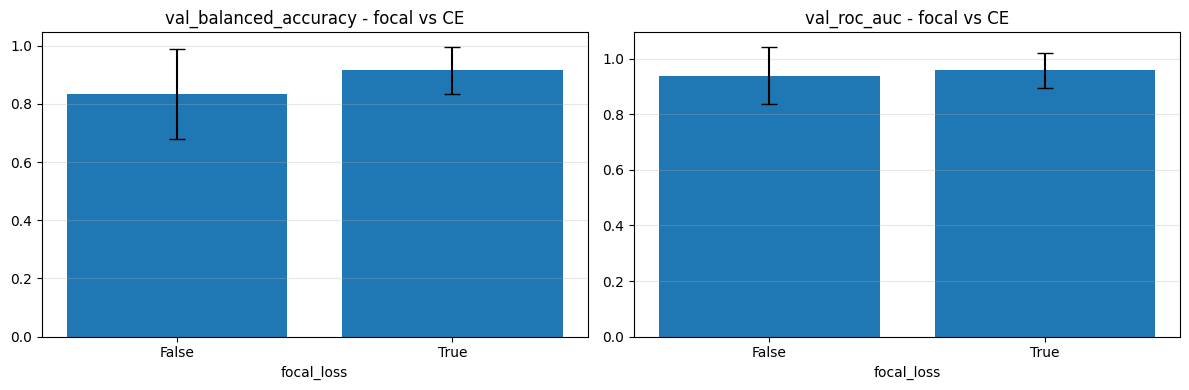

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["val_balanced_accuracy", "val_roc_auc"]):
    m = df.groupby("focal_loss")[metric].mean()
    s = df.groupby("focal_loss")[metric].std()
    ax.bar(m.index.astype(str), m.values, yerr=s.values, capsize=6)
    ax.set_title(f"{metric} - focal vs CE"); ax.set_xlabel("focal_loss")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## Evaluation finale sur le test (une seule fois)

In [21]:
best_model = build_model(best_candidate["config"]).to(DEVICE)
best_model.load_state_dict(best_candidate["model_state_dict"])
nm = best_candidate["normalization"]
if nm["mode"] == "per_segment":
    m = x_test.mean(axis=1, keepdims=True)
    s = np.maximum(x_test.std(axis=1, keepdims=True), 1e-8)
    x_test_norm = (x_test - m) / s
else:
    x_test_norm = (x_test - nm["mean_train"]) / nm["std_train"]
crit = make_loss(np.array([0, 1]), best_candidate["focal_loss"]).to(DEVICE)
tml = make_loader(x_test_norm, y_test, shuffle=False)
tmet = evaluate(best_model, tml, crit)
print("=== Test final ===")
print(json.dumps({k: v for k, v in tmet.items() if k != "confusion_matrix"}, indent=2))
print("Confusion [0=non-ictal, 1=ictal]:"); print(np.array(tmet["confusion_matrix"]))

=== Test final ===
{
  "loss": 0.07363037099130451,
  "accuracy": 0.975,
  "balanced_accuracy": 0.975,
  "precision_ictal": 1.0,
  "recall_sensitivity_ictal": 0.95,
  "specificity_non_ictal": 1.0,
  "f1_ictal": 0.9743589743589743,
  "roc_auc": 1.0
}
Confusion [0=non-ictal, 1=ictal]:
[[20  0]
 [ 1 19]]
